In [1]:
# Cell 1 — Environment check

import os
import sys
import platform

print("Python version:")
print(sys.version)

print("\nPlatform:")
print(platform.platform())

print("\nCPU cores:")
print(os.cpu_count())

print("\nOperating system:")
!cat /etc/os-release | grep PRETTY_NAME

print("\nGPU information:")
!nvidia-smi

Python version:
3.12.13 (main, Mar  4 2026, 09:23:07) [GCC 11.4.0]

Platform:
Linux-6.6.122+-x86_64-with-glibc2.35

CPU cores:
8

Operating system:
PRETTY_NAME="Ubuntu 22.04.5 LTS"

GPU information:
Sat Sep 26 10:43:12 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   41C    P8              9W

In [2]:
# Cell 2 — Install and import required libraries

!pip install -q tensorflow_decision_forests==1.12.0

import os
import time
import gc

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
import tensorflow_decision_forests as tfdf

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    matthews_corrcoef,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("TensorFlow version:", tf.__version__)
print("TensorFlow Decision Forests version:", tfdf.__version__)

TensorFlow version: 2.19.0
TensorFlow Decision Forests version: 1.12.0


In [3]:
# Cell 3 — Mount Google Drive

from google.colab import drive

drive.mount(
    "/content/drive"
)

print(
    "Google Drive mounted."
)

Mounted at /content/drive
Google Drive mounted.


In [4]:
# Cell 4 — Define project paths

PROJECT_DIR = (
    "/content/drive/MyDrive/MSc_Project"
)

PROCESSED_DIR = os.path.join(
    PROJECT_DIR,
    "data",
    "CICIDS2017",
    "processed"
)

RESULTS_DIR = os.path.join(
    PROJECT_DIR,
    "results",
    "RF_H3_CIC"
)

MODEL_DIR = os.path.join(
    PROJECT_DIR,
    "models",
    "RF_H3_CIC"
)

os.makedirs(
    RESULTS_DIR,
    exist_ok=True
)

os.makedirs(
    MODEL_DIR,
    exist_ok=True
)

TRAIN_PATH = os.path.join(
    PROCESSED_DIR,
    "cicids2017_train.parquet"
)

VAL_PATH = os.path.join(
    PROCESSED_DIR,
    "cicids2017_validation.parquet"
)

TEST_PATH = os.path.join(
    PROCESSED_DIR,
    "cicids2017_test.parquet"
)

# Frozen validation references

H1_VALIDATION_PATH = os.path.join(
    PROJECT_DIR,
    "results",
    "RF_H1_CIC",
    "RF_H1_validation_comparison.csv"
)

H2_VALIDATION_PATH = os.path.join(
    PROJECT_DIR,
    "results",
    "RF_H2_CIC",
    "RF_H2_min_examples_comparison.csv"
)

LABEL_COL = "Label"

print("Project directory:")
print(PROJECT_DIR)

print("\nH3 results directory:")
print(RESULTS_DIR)

print("\nH3 model directory:")
print(MODEL_DIR)

Project directory:
/content/drive/MyDrive/MSc_Project

H3 results directory:
/content/drive/MyDrive/MSc_Project/results/RF_H3_CIC

H3 model directory:
/content/drive/MyDrive/MSc_Project/models/RF_H3_CIC


In [5]:
# Cell 5 — Verify frozen datasets and validation references

required_files = {
    "CIC training set": TRAIN_PATH,
    "CIC validation set": VAL_PATH,
    "CIC test set": TEST_PATH,
    "RF-H1 validation results": H1_VALIDATION_PATH,
    "RF-H2 validation results": H2_VALIDATION_PATH
}

print(
    "Frozen input file checks:\n"
)

all_files_exist = True

for name, path in required_files.items():

    exists = os.path.exists(
        path
    )

    print(
        f"{name}: {exists}"
    )

    if not exists:
        print(
            f"  Missing: {path}"
        )

        all_files_exist = False

print(
    "\nAll required files available:",
    all_files_exist
)

if not all_files_exist:
    raise FileNotFoundError(
        "One or more required frozen files "
        "are missing. Stop here."
    )

Frozen input file checks:

CIC training set: True
CIC validation set: True
CIC test set: True
RF-H1 validation results: True
RF-H2 validation results: True

All required files available: True


In [6]:
# Cell 6 — Load frozen CIC-IDS2017 datasets

print("Loading frozen CIC-IDS2017 datasets...")

train_df = pd.read_parquet(
    TRAIN_PATH
)

val_df = pd.read_parquet(
    VAL_PATH
)

test_df = pd.read_parquet(
    TEST_PATH
)

print("\nDataset shapes:")

print(
    "Train:",
    train_df.shape
)

print(
    "Validation:",
    val_df.shape
)

print(
    "Test:",
    test_df.shape
)

print(
    "\nLabel column:",
    LABEL_COL
)

print(
    "\nNumber of input features:",
    train_df.shape[1] - 1
)

print(
    "\nMissing values:"
)

print(
    "Train:",
    int(train_df.isna().sum().sum())
)

print(
    "Validation:",
    int(val_df.isna().sum().sum())
)

print(
    "Test:",
    int(test_df.isna().sum().sum())
)

Loading frozen CIC-IDS2017 datasets...

Dataset shapes:
Train: (1764554, 79)
Validation: (378119, 79)
Test: (378119, 79)

Label column: Label

Number of input features: 78

Missing values:
Train: 0
Validation: 0
Test: 0


In [7]:
# Cell 7 — Define frozen class order and perform sanity checks

CLASS_NAMES = [
    "BENIGN",
    "Bot",
    "DDoS",
    "DoS GoldenEye",
    "DoS Hulk",
    "DoS Slowhttptest",
    "DoS slowloris",
    "FTP-Patator",
    "Heartbleed",
    "Infiltration",
    "PortScan",
    "SSH-Patator",
    "Web Attack - Brute Force",
    "Web Attack - SQL Injection",
    "Web Attack - XSS"
]

CLASS_TO_INDEX = {
    class_name: index
    for index, class_name
    in enumerate(CLASS_NAMES)
}

print(
    "Number of expected classes:",
    len(CLASS_NAMES)
)

print(
    "\nClass order:"
)

for index, class_name in enumerate(CLASS_NAMES):
    print(
        index,
        class_name
    )

train_classes = set(
    train_df[LABEL_COL].unique()
)

val_classes = set(
    val_df[LABEL_COL].unique()
)

test_classes = set(
    test_df[LABEL_COL].unique()
)

expected_classes = set(
    CLASS_NAMES
)

print(
    "\nTrain classes match expected:",
    train_classes == expected_classes
)

print(
    "Validation classes match expected:",
    val_classes == expected_classes
)

print(
    "Test classes match expected:",
    test_classes == expected_classes
)

print(
    "\nTraining class distribution:"
)

display(
    train_df[LABEL_COL]
    .value_counts()
    .reindex(CLASS_NAMES)
    .to_frame("Count")
)

Number of expected classes: 15

Class order:
0 BENIGN
1 Bot
2 DDoS
3 DoS GoldenEye
4 DoS Hulk
5 DoS Slowhttptest
6 DoS slowloris
7 FTP-Patator
8 Heartbleed
9 Infiltration
10 PortScan
11 SSH-Patator
12 Web Attack - Brute Force
13 Web Attack - SQL Injection
14 Web Attack - XSS

Train classes match expected: True
Validation classes match expected: True
Test classes match expected: True

Training class distribution:


,Count
Label,
BENIGN,1466535
Bot,1364
DDoS,89610
DoS GoldenEye,7200
DoS Hulk,120992
DoS Slowhttptest,3660
DoS slowloris,3769
FTP-Patator,4152
Heartbleed,8


In [8]:
# Cell 8 — Convert frozen dataframes to TensorFlow Decision Forest datasets

print(
    "Creating TensorFlow Decision Forest datasets..."
)

train_ds = tfdf.keras.pd_dataframe_to_tf_dataset(
    train_df,
    label=LABEL_COL,
    task=tfdf.keras.Task.CLASSIFICATION
)

val_ds = tfdf.keras.pd_dataframe_to_tf_dataset(
    val_df,
    label=LABEL_COL,
    task=tfdf.keras.Task.CLASSIFICATION
)

# The test dataset is prepared but will NOT be evaluated
# until the H3 configuration has been locked.
test_ds = tfdf.keras.pd_dataframe_to_tf_dataset(
    test_df,
    label=LABEL_COL,
    task=tfdf.keras.Task.CLASSIFICATION
)

print(
    "TF-DF datasets created successfully."
)

print(
    "\nTraining records:",
    len(train_df)
)

print(
    "Validation records:",
    len(val_df)
)

print(
    "Held-out test records:",
    len(test_df)
)

Creating TensorFlow Decision Forest datasets...


TF-DF datasets created successfully.

Training records: 1764554
Validation records: 378119
Held-out test records: 378119


In [9]:
# Cell 9 — Load frozen H1 and H2 validation references

h1_validation_df = pd.read_csv(
    H1_VALIDATION_PATH
)

h2_validation_df = pd.read_csv(
    H2_VALIDATION_PATH
)

print(
    "RF-H1 validation results:"
)

display(
    h1_validation_df
)

print(
    "\nRF-H2 Stage B validation results:"
)

display(
    h2_validation_df
)

# --------------------------------------------------
# Select frozen H1 winner by validation Macro F1
# --------------------------------------------------

h1_best_index = (
    h1_validation_df["Macro F1"]
    .idxmax()
)

h1_best_row = (
    h1_validation_df
    .loc[h1_best_index]
)

# --------------------------------------------------
# Select frozen H2 winner by validation Macro F1
# --------------------------------------------------

h2_best_index = (
    h2_validation_df["Macro F1"]
    .idxmax()
)

h2_best_row = (
    h2_validation_df
    .loc[h2_best_index]
)

print(
    "\nFrozen RF-H1 winner:"
)

print(
    h1_best_row
)

print(
    "\nFrozen RF-H2 winner:"
)

print(
    h2_best_row
)

# --------------------------------------------------
# Extract selected settings
# --------------------------------------------------

H1_BEST_TREES = int(
    h1_best_row["Trees"]
)

H2_BEST_DEPTH = int(
    h2_best_row["Max Depth"]
    if "Max Depth" in h2_best_row.index
    else h2_best_row["max_depth"]
)

H2_BEST_MIN_EXAMPLES = int(
    h2_best_row["Min Examples"]
    if "Min Examples" in h2_best_row.index
    else h2_best_row["min_examples"]
)

print(
    "\nSettings to combine in RF-H3-CIC:"
)

print(
    "num_trees:",
    H1_BEST_TREES
)

print(
    "max_depth:",
    H2_BEST_DEPTH
)

print(
    "min_examples:",
    H2_BEST_MIN_EXAMPLES
)

RF-H1 validation results:


,Trees,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,Balanced Accuracy,MCC,Training Time Seconds
0,300,0.998543,0.942492,0.842749,0.877171,0.998515,0.842749,0.995153,748.276625
1,200,0.998556,0.942576,0.842280,0.876783,0.998527,0.842280,0.995197,521.687147
2,100,0.998553,0.941933,0.831298,0.865672,0.998526,0.831298,0.995188,298.754683



RF-H2 Stage B validation results:


,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,Balanced Accuracy,MCC,Max Depth,Min Examples,Trees,Training Time Seconds
0,0.998670,0.944180,0.848268,0.881331,0.998625,0.848268,0.995576,30,1,100,315.334803
1,0.998797,0.955151,0.837496,0.872920,0.998739,0.837496,0.995999,30,2,100,304.751500
2,0.998844,0.951324,0.816638,0.855450,0.998796,0.816638,0.996158,30,5,100,295.971193
3,0.998839,0.887744,0.784190,0.812338,0.998788,0.784190,0.996140,30,10,100,312.385086



Frozen RF-H1 winner:
Trees                    300.000000
Accuracy                   0.998543
Macro Precision            0.942492
Macro Recall               0.842749
Macro F1                   0.877171
Weighted F1                0.998515
Balanced Accuracy          0.842749
MCC                        0.995153
Training Time Seconds    748.276625
Name: 0, dtype: float64

Frozen RF-H2 winner:
Accuracy                   0.998670
Macro Precision            0.944180
Macro Recall               0.848268
Macro F1                   0.881331
Weighted F1                0.998625
Balanced Accuracy          0.848268
MCC                        0.995576
Max Depth                 30.000000
Min Examples               1.000000
Trees                    100.000000
Training Time Seconds    315.334803
Name: 0, dtype: float64

Settings to combine in RF-H3-CIC:
num_trees: 300
max_depth: 30
min_examples: 1


In [10]:
# Cell 10 — Define RF-H3-CIC configuration
# and validation evaluation helper

H3_NUM_TREES = H1_BEST_TREES
H3_MAX_DEPTH = H2_BEST_DEPTH
H3_MIN_EXAMPLES = H2_BEST_MIN_EXAMPLES
H3_RANDOM_SEED = 42

print(
    "RF-H3-CIC configuration"
)

print(
    "Trees:",
    H3_NUM_TREES
)

print(
    "Max depth:",
    H3_MAX_DEPTH
)

print(
    "Min examples:",
    H3_MIN_EXAMPLES
)

print(
    "Random seed:",
    H3_RANDOM_SEED
)

print(
    "\nOther Random Forest settings remain "
    "identical to the frozen baseline."
)


def evaluate_multiclass_model(
    model,
    dataset,
    true_labels,
    class_names
):
    """
    Evaluate a multiclass TF-DF model using the
    project's fixed IDS metrics.
    """

    probabilities = model.predict(
        dataset,
        verbose=0
    )

    predicted_indices = np.argmax(
        probabilities,
        axis=1
    )

    class_to_index = {
        class_name: index
        for index, class_name
        in enumerate(class_names)
    }

    true_indices = np.array([
        class_to_index[label]
        for label in true_labels
    ])

    results = {
        "Accuracy": accuracy_score(
            true_indices,
            predicted_indices
        ),

        "Macro Precision": precision_score(
            true_indices,
            predicted_indices,
            average="macro",
            zero_division=0
        ),

        "Macro Recall": recall_score(
            true_indices,
            predicted_indices,
            average="macro",
            zero_division=0
        ),

        "Macro F1": f1_score(
            true_indices,
            predicted_indices,
            average="macro",
            zero_division=0
        ),

        "Weighted F1": f1_score(
            true_indices,
            predicted_indices,
            average="weighted",
            zero_division=0
        ),

        "Balanced Accuracy": balanced_accuracy_score(
            true_indices,
            predicted_indices
        ),

        "MCC": matthews_corrcoef(
            true_indices,
            predicted_indices
        )
    }

    return (
        results,
        true_indices,
        predicted_indices,
        probabilities
    )


print(
    "\nEvaluation helper ready."
)

RF-H3-CIC configuration
Trees: 300
Max depth: 30
Min examples: 1
Random seed: 42

Other Random Forest settings remain identical to the frozen baseline.

Evaluation helper ready.


In [11]:
# Cell 11 — Train RF-H3-CIC
# Combined hyperparameter configuration selected from H1 and H2

print("Training RF-H3-CIC...")
print()
print("Configuration:")
print("  num_trees:", H3_NUM_TREES)
print("  max_depth:", H3_MAX_DEPTH)
print("  min_examples:", H3_MIN_EXAMPLES)
print("  random_seed:", H3_RANDOM_SEED)

rf_h3_cic = tfdf.keras.RandomForestModel(
    num_trees=H3_NUM_TREES,
    max_depth=H3_MAX_DEPTH,
    min_examples=H3_MIN_EXAMPLES,

    # Same baseline RF behaviour
    num_candidate_attributes=0,
    bootstrap_training_dataset=True,
    bootstrap_size_ratio=1.0,
    sampling_with_replacement=True,

    # Reproducibility
    random_seed=H3_RANDOM_SEED,

    # Internal RF diagnostics
    compute_oob_performances=True,

    # Use available CPU threads
    num_threads=8,

    verbose=2
)

rf_h3_cic.compile(
    metrics=["accuracy"]
)

# --------------------------------------------------
# Train model and measure wall-clock training time
# --------------------------------------------------

h3_training_start = time.time()

rf_h3_cic.fit(
    train_ds
)

H3_TRAINING_TIME = (
    time.time() - h3_training_start
)

print(
    "\nRF-H3-CIC training complete."
)

print(
    "Training time:",
    round(H3_TRAINING_TIME, 6),
    "seconds"
)

print(
    "\nTraining time in minutes:",
    round(H3_TRAINING_TIME / 60, 2)
)

Training RF-H3-CIC...

Configuration:
  num_trees: 300
  max_depth: 30
  min_examples: 1
  random_seed: 42
Use /tmp/tmpgpihl8yg as temporary training directory
Reading training dataset...
Training tensor examples:
Features: {'Destination_Port': <tf.Tensor 'data:0' shape=(None,) dtype=float32>, 'Flow_Duration': <tf.Tensor 'data_1:0' shape=(None,) dtype=float64>, 'Total_Fwd_Packets': <tf.Tensor 'data_2:0' shape=(None,) dtype=float32>, 'Total_Backward_Packets': <tf.Tensor 'data_3:0' shape=(None,) dtype=float32>, 'Total_Length_of_Fwd_Packets': <tf.Tensor 'data_4:0' shape=(None,) dtype=float32>, 'Total_Length_of_Bwd_Packets': <tf.Tensor 'data_5:0' shape=(None,) dtype=float64>, 'Fwd_Packet_Length_Max': <tf.Tensor 'data_6:0' shape=(None,) dtype=float32>, 'Fwd_Packet_Length_Min': <tf.Tensor 'data_7:0' shape=(None,) dtype=float32>, 'Fwd_Packet_Length_Mean': <tf.Tensor 'data_8:0' shape=(None,) dtype=float32>, 'Fwd_Packet_Length_Std': <tf.Tensor 'data_9:0' shape=(None,) dtype=float32>, 'Bwd_Packe

I0000 00:00:1790420185.578195     268 kernel.cc:782] Start Yggdrasil model training
I0000 00:00:1790420185.578532     268 kernel.cc:783] Collect training examples
I0000 00:00:1790420185.578547     268 kernel.cc:795] Dataspec guide:
column_guides {
  column_name_pattern: "^__LABEL$"
  type: CATEGORICAL
  categorial {
    min_vocab_frequency: 0
    max_vocab_count: -1
  }
}
default_column_guide {
  categorial {
    max_vocab_count: 2000
  }
  discretized_numerical {
    maximum_num_bins: 255
  }
}
ignore_columns_without_guides: false
detect_numerical_as_discretized_numerical: false

I0000 00:00:1790420185.579127     268 kernel.cc:401] Number of batches: 1765
I0000 00:00:1790420185.579141     268 kernel.cc:402] Number of examples: 1764554
I0000 00:00:1790420186.594803     268 kernel.cc:802] Training dataset:
Number of records: 1764554
Number of columns: 79

Number of columns by type:
	NUMERICAL: 78 (98.7342%)
	CATEGORICAL: 1 (1.26582%)

Columns:

NUMERICAL: 78 (98.7342%)
	0: "ACK_Flag_Cou

Model trained in 0:10:47.169766
Compiling model...
Model compiled.

RF-H3-CIC training complete.
Training time: 714.444308 seconds

Training time in minutes: 11.91


In [12]:
# Cell 12 — Evaluate RF-H3-CIC on validation data

print(
    "Evaluating RF-H3-CIC on validation set..."
)

(
    results_h3_val,
    y_val_true,
    y_val_pred,
    h3_val_probabilities
) = evaluate_multiclass_model(
    model=rf_h3_cic,
    dataset=val_ds,
    true_labels=val_df[LABEL_COL].values,
    class_names=CLASS_NAMES
)

# Add frozen configuration details
results_h3_val["Trees"] = H3_NUM_TREES
results_h3_val["Max Depth"] = H3_MAX_DEPTH
results_h3_val["Min Examples"] = H3_MIN_EXAMPLES
results_h3_val["Training Time Seconds"] = H3_TRAINING_TIME

print(
    "\nRF-H3-CIC Validation Results"
)

print(
    "Accuracy:",
    f"{results_h3_val['Accuracy']:.6f}"
)

print(
    "Macro Precision:",
    f"{results_h3_val['Macro Precision']:.6f}"
)

print(
    "Macro Recall:",
    f"{results_h3_val['Macro Recall']:.6f}"
)

print(
    "Macro F1:",
    f"{results_h3_val['Macro F1']:.6f}"
)

print(
    "Weighted F1:",
    f"{results_h3_val['Weighted F1']:.6f}"
)

print(
    "Balanced Accuracy:",
    f"{results_h3_val['Balanced Accuracy']:.6f}"
)

print(
    "MCC:",
    f"{results_h3_val['MCC']:.6f}"
)

print(
    "\nConfiguration:"
)

print(
    "Trees:",
    H3_NUM_TREES
)

print(
    "Max Depth:",
    H3_MAX_DEPTH
)

print(
    "Min Examples:",
    H3_MIN_EXAMPLES
)

print(
    "Training Time Seconds:",
    f"{H3_TRAINING_TIME:.6f}"
)

Evaluating RF-H3-CIC on validation set...

RF-H3-CIC Validation Results
Accuracy: 0.998678
Macro Precision: 0.948418
Macro Recall: 0.839507
Macro F1: 0.875575
Weighted F1: 0.998635
Balanced Accuracy: 0.839507
MCC: 0.995603

Configuration:
Trees: 300
Max Depth: 30
Min Examples: 1
Training Time Seconds: 714.444308


In [13]:
# Cell 13 — Save RF-H3-CIC validation results

H3_VALIDATION_PATH = os.path.join(
    RESULTS_DIR,
    "RF_H3_validation.csv"
)

h3_validation_df = pd.DataFrame([
    {
        "Model": "RF-H3-CIC",
        "Trees": H3_NUM_TREES,
        "Max Depth": H3_MAX_DEPTH,
        "Min Examples": H3_MIN_EXAMPLES,
        "Accuracy": results_h3_val["Accuracy"],
        "Macro Precision": results_h3_val["Macro Precision"],
        "Macro Recall": results_h3_val["Macro Recall"],
        "Macro F1": results_h3_val["Macro F1"],
        "Weighted F1": results_h3_val["Weighted F1"],
        "Balanced Accuracy": results_h3_val[
            "Balanced Accuracy"
        ],
        "MCC": results_h3_val["MCC"],
        "Training Time Seconds": H3_TRAINING_TIME
    }
])

h3_validation_df.to_csv(
    H3_VALIDATION_PATH,
    index=False
)

print(
    "RF-H3-CIC validation results saved to:"
)

print(
    H3_VALIDATION_PATH
)

print(
    "\nSaved validation result:"
)

display(
    h3_validation_df
)

print(
    "\nFile exists:",
    os.path.exists(H3_VALIDATION_PATH)
)

RF-H3-CIC validation results saved to:
/content/drive/MyDrive/MSc_Project/results/RF_H3_CIC/RF_H3_validation.csv

Saved validation result:


,Model,Trees,Max Depth,Min Examples,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,Balanced Accuracy,MCC,Training Time Seconds
0,RF-H3-CIC,300,30,1,0.998678,0.948418,0.839507,0.875575,0.998635,0.839507,0.995603,714.444308



File exists: True


In [14]:
# Cell 14 — Compare RF-H1, RF-H2 and RF-H3
# using VALIDATION results only

tuned_validation_comparison = pd.DataFrame([
    {
        "Model": "RF-H1-CIC",
        "Trees": int(h1_best_row["Trees"]),
        "Max Depth": "Unlimited",
        "Min Examples": 1,
        "Accuracy": h1_best_row["Accuracy"],
        "Macro Precision": h1_best_row[
            "Macro Precision"
        ],
        "Macro Recall": h1_best_row[
            "Macro Recall"
        ],
        "Macro F1": h1_best_row[
            "Macro F1"
        ],
        "Weighted F1": h1_best_row[
            "Weighted F1"
        ],
        "Balanced Accuracy": h1_best_row[
            "Balanced Accuracy"
        ],
        "MCC": h1_best_row["MCC"],
        "Training Time Seconds": h1_best_row[
            "Training Time Seconds"
        ]
    },

    {
        "Model": "RF-H2-CIC",
        "Trees": int(h2_best_row["Trees"]),
        "Max Depth": int(
            h2_best_row["Max Depth"]
        ),
        "Min Examples": int(
            h2_best_row["Min Examples"]
        ),
        "Accuracy": h2_best_row["Accuracy"],
        "Macro Precision": h2_best_row[
            "Macro Precision"
        ],
        "Macro Recall": h2_best_row[
            "Macro Recall"
        ],
        "Macro F1": h2_best_row[
            "Macro F1"
        ],
        "Weighted F1": h2_best_row[
            "Weighted F1"
        ],
        "Balanced Accuracy": h2_best_row[
            "Balanced Accuracy"
        ],
        "MCC": h2_best_row["MCC"],
        "Training Time Seconds": h2_best_row[
            "Training Time Seconds"
        ]
    },

    {
        "Model": "RF-H3-CIC",
        "Trees": H3_NUM_TREES,
        "Max Depth": H3_MAX_DEPTH,
        "Min Examples": H3_MIN_EXAMPLES,
        "Accuracy": results_h3_val[
            "Accuracy"
        ],
        "Macro Precision": results_h3_val[
            "Macro Precision"
        ],
        "Macro Recall": results_h3_val[
            "Macro Recall"
        ],
        "Macro F1": results_h3_val[
            "Macro F1"
        ],
        "Weighted F1": results_h3_val[
            "Weighted F1"
        ],
        "Balanced Accuracy": results_h3_val[
            "Balanced Accuracy"
        ],
        "MCC": results_h3_val["MCC"],
        "Training Time Seconds": H3_TRAINING_TIME
    }
])

# Sort according to the project's primary
# validation selection metric
tuned_validation_comparison = (
    tuned_validation_comparison
    .sort_values(
        by="Macro F1",
        ascending=False
    )
    .reset_index(drop=True)
)

TUNED_COMPARISON_PATH = os.path.join(
    RESULTS_DIR,
    "RF_H1_vs_RF_H2_vs_RF_H3_validation_comparison.csv"
)

tuned_validation_comparison.to_csv(
    TUNED_COMPARISON_PATH,
    index=False
)

print(
    "RF-H1 vs RF-H2 vs RF-H3 "
    "Validation Comparison"
)

display(
    tuned_validation_comparison
)

print(
    "\nPrimary selection metric: Macro F1"
)

print(
    "\nComparison saved to:"
)

print(
    TUNED_COMPARISON_PATH
)

RF-H1 vs RF-H2 vs RF-H3 Validation Comparison


,Model,Trees,Max Depth,Min Examples,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,Balanced Accuracy,MCC,Training Time Seconds
0,RF-H2-CIC,100,30,1,0.998670,0.944180,0.848268,0.881331,0.998625,0.848268,0.995576,315.334803
1,RF-H1-CIC,300,Unlimited,1,0.998543,0.942492,0.842749,0.877171,0.998515,0.842749,0.995153,748.276625
2,RF-H3-CIC,300,30,1,0.998678,0.948418,0.839507,0.875575,0.998635,0.839507,0.995603,714.444308



Primary selection metric: Macro F1

Comparison saved to:
/content/drive/MyDrive/MSc_Project/results/RF_H3_CIC/RF_H1_vs_RF_H2_vs_RF_H3_validation_comparison.csv


In [15]:
# Cell 15 — Lock best tuned Random Forest configuration
# Selection is based ONLY on validation Macro F1

best_tuned_row = (
    tuned_validation_comparison
    .iloc[0]
)

BEST_TUNED_MODEL = (
    best_tuned_row["Model"]
)

BEST_TUNED_VALIDATION_MACRO_F1 = float(
    best_tuned_row["Macro F1"]
)

# --------------------------------------------------
# Resolve the selected configuration
# --------------------------------------------------

if BEST_TUNED_MODEL == "RF-H1-CIC":

    BEST_TUNED_TREES = 300
    BEST_TUNED_MAX_DEPTH = -1
    BEST_TUNED_MIN_EXAMPLES = 1

elif BEST_TUNED_MODEL == "RF-H2-CIC":

    BEST_TUNED_TREES = 100
    BEST_TUNED_MAX_DEPTH = 30
    BEST_TUNED_MIN_EXAMPLES = 1

elif BEST_TUNED_MODEL == "RF-H3-CIC":

    BEST_TUNED_TREES = 300
    BEST_TUNED_MAX_DEPTH = 30
    BEST_TUNED_MIN_EXAMPLES = 1

else:

    raise ValueError(
        "Unexpected tuned model selection."
    )

BEST_TUNED_RANDOM_SEED = 42

print(
    "BEST TUNED RANDOM FOREST CONFIGURATION LOCKED"
)

print(
    "\nSelected model:",
    BEST_TUNED_MODEL
)

print(
    "Validation Macro F1:",
    f"{BEST_TUNED_VALIDATION_MACRO_F1:.6f}"
)

print(
    "\nFrozen configuration:"
)

print(
    "Trees:",
    BEST_TUNED_TREES
)

print(
    "Max depth:",
    BEST_TUNED_MAX_DEPTH
)

print(
    "Min examples:",
    BEST_TUNED_MIN_EXAMPLES
)

print(
    "Random seed:",
    BEST_TUNED_RANDOM_SEED
)

print(
    "\nIMPORTANT:"
)

print(
    "This selection was made using validation "
    "Macro F1 only."
)

print(
    "No held-out H3 test result was used "
    "for model selection."
)

BEST TUNED RANDOM FOREST CONFIGURATION LOCKED

Selected model: RF-H2-CIC
Validation Macro F1: 0.881331

Frozen configuration:
Trees: 100
Max depth: 30
Min examples: 1
Random seed: 42

IMPORTANT:
This selection was made using validation Macro F1 only.
No held-out H3 test result was used for model selection.


In [16]:
# Cell 16 — Save RF-H3-CIC model
# and locked best-tuning configuration

import shutil

# --------------------------------------------------
# 1. Save RF-H3-CIC model
# --------------------------------------------------

H3_MODEL_PATH = os.path.join(
    MODEL_DIR,
    "saved_model"
)

# Remove previous copy only if this cell is rerun
if os.path.exists(H3_MODEL_PATH):
    shutil.rmtree(H3_MODEL_PATH)

rf_h3_cic.save(
    H3_MODEL_PATH
)

print(
    "RF-H3-CIC model saved to:"
)

print(
    H3_MODEL_PATH
)

# --------------------------------------------------
# 2. Save locked best-tuned configuration
# --------------------------------------------------

BEST_TUNED_CONFIG_PATH = os.path.join(
    RESULTS_DIR,
    "RF_best_tuned_configuration.csv"
)

best_tuned_config_df = pd.DataFrame([
    {
        "Selected Model": BEST_TUNED_MODEL,
        "Trees": BEST_TUNED_TREES,
        "Max Depth": BEST_TUNED_MAX_DEPTH,
        "Min Examples": BEST_TUNED_MIN_EXAMPLES,
        "Random Seed": BEST_TUNED_RANDOM_SEED,
        "Selection Metric": "Validation Macro F1",
        "Validation Macro F1":
            BEST_TUNED_VALIDATION_MACRO_F1
    }
])

best_tuned_config_df.to_csv(
    BEST_TUNED_CONFIG_PATH,
    index=False
)

print(
    "\nLocked best-tuned configuration:"
)

display(
    best_tuned_config_df
)

print(
    "\nSaved to:"
)

print(
    BEST_TUNED_CONFIG_PATH
)

# --------------------------------------------------
# 3. Checks
# --------------------------------------------------

print(
    "\nChecks:"
)

print(
    "H3 model exists:",
    os.path.exists(H3_MODEL_PATH)
)

print(
    "Best-tuning configuration exists:",
    os.path.exists(BEST_TUNED_CONFIG_PATH)
)

RF-H3-CIC model saved to:
/content/drive/MyDrive/MSc_Project/models/RF_H3_CIC/saved_model

Locked best-tuned configuration:


,Selected Model,Trees,Max Depth,Min Examples,Random Seed,Selection Metric,Validation Macro F1
0,RF-H2-CIC,100,30,1,42,Validation Macro F1,0.881331



Saved to:
/content/drive/MyDrive/MSc_Project/results/RF_H3_CIC/RF_best_tuned_configuration.csv

Checks:
H3 model exists: True
Best-tuning configuration exists: True


In [17]:
# Cell 17 — Final held-out test evaluation
# RF-H3-CIC
#
# IMPORTANT:
# The best tuned RF configuration was locked
# using validation results BEFORE this test evaluation.

print(
    "Evaluating RF-H3-CIC on held-out test set..."
)

(
    results_h3_test,
    y_test_true,
    y_test_pred_h3,
    h3_test_probabilities
) = evaluate_multiclass_model(
    model=rf_h3_cic,
    dataset=test_ds,
    true_labels=test_df[LABEL_COL].values,
    class_names=CLASS_NAMES
)

print(
    "\nRF-H3-CIC Final Held-Out Test Results"
)

print(
    "Accuracy:",
    f"{results_h3_test['Accuracy']:.6f}"
)

print(
    "Macro Precision:",
    f"{results_h3_test['Macro Precision']:.6f}"
)

print(
    "Macro Recall:",
    f"{results_h3_test['Macro Recall']:.6f}"
)

print(
    "Macro F1:",
    f"{results_h3_test['Macro F1']:.6f}"
)

print(
    "Weighted F1:",
    f"{results_h3_test['Weighted F1']:.6f}"
)

print(
    "Balanced Accuracy:",
    f"{results_h3_test['Balanced Accuracy']:.6f}"
)

print(
    "MCC:",
    f"{results_h3_test['MCC']:.6f}"
)

print(
    "\nConfiguration:"
)

print(
    "Trees:",
    H3_NUM_TREES
)

print(
    "Max depth:",
    H3_MAX_DEPTH
)

print(
    "Min examples:",
    H3_MIN_EXAMPLES
)

print(
    "Training time:",
    f"{H3_TRAINING_TIME:.6f}",
    "seconds"
)

Evaluating RF-H3-CIC on held-out test set...

RF-H3-CIC Final Held-Out Test Results
Accuracy: 0.998738
Macro Precision: 0.935066
Macro Recall: 0.875289
Macro F1: 0.889257
Weighted F1: 0.998684
Balanced Accuracy: 0.875289
MCC: 0.995805

Configuration:
Trees: 300
Max depth: 30
Min examples: 1
Training time: 714.444308 seconds


In [18]:
# Cell 18 — RF-H3-CIC classification report

H3_REPORT_PATH = os.path.join(
    RESULTS_DIR,
    "RF_H3_CIC_classification_report.csv"
)

h3_report_dict = classification_report(
    y_test_true,
    y_test_pred_h3,
    labels=list(range(len(CLASS_NAMES))),
    target_names=CLASS_NAMES,
    output_dict=True,
    zero_division=0
)

h3_report_df = (
    pd.DataFrame(h3_report_dict)
    .transpose()
)

h3_report_df.to_csv(
    H3_REPORT_PATH,
    index=True
)

print(
    "RF-H3-CIC Classification Report"
)

display(
    h3_report_df
)

print(
    "\nClassification report saved to:"
)

print(
    H3_REPORT_PATH
)

print(
    "\nFile exists:",
    os.path.exists(H3_REPORT_PATH)
)

RF-H3-CIC Classification Report


,precision,recall,f1-score,support
BENIGN,0.999484,0.999383,0.999434,314258.000000
Bot,0.906504,0.763699,0.828996,292.000000
DDoS,0.999896,0.999948,0.999922,19202.000000
DoS GoldenEye,0.999347,0.992223,0.995772,1543.000000
DoS Hulk,0.998573,0.998920,0.998747,25927.000000
DoS Slowhttptest,0.988608,0.996173,0.992376,784.000000
DoS slowloris,0.995037,0.992574,0.993804,808.000000
FTP-Patator,1.000000,0.996629,0.998312,890.000000
Heartbleed,1.000000,1.000000,1.000000,1.000000
Infiltration,1.000000,1.000000,1.000000,5.000000



Classification report saved to:
/content/drive/MyDrive/MSc_Project/results/RF_H3_CIC/RF_H3_CIC_classification_report.csv

File exists: True


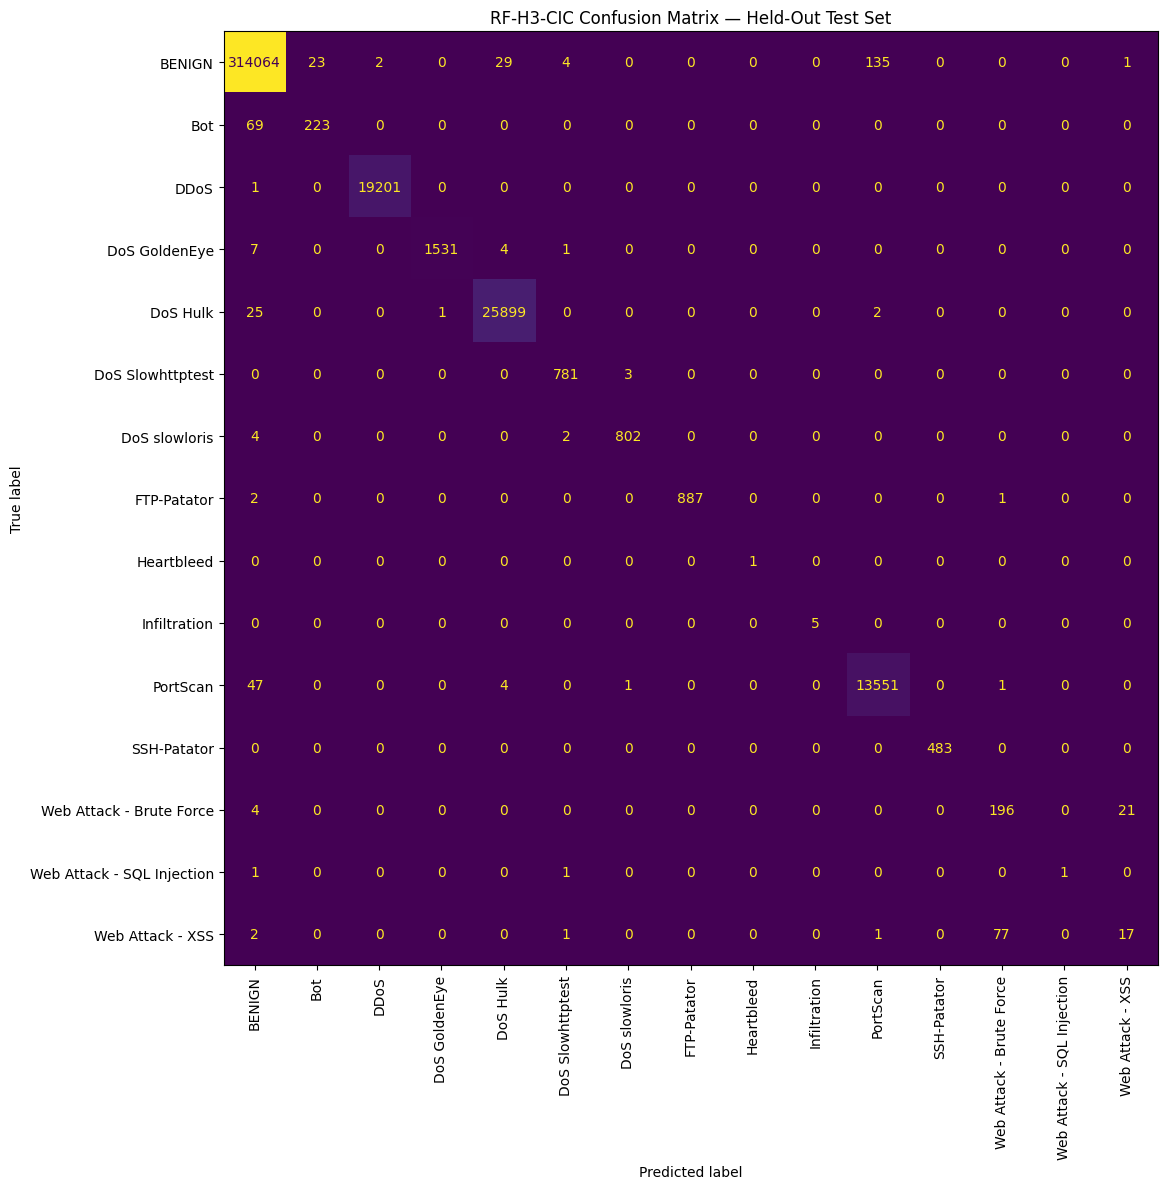


Confusion matrix saved to:
/content/drive/MyDrive/MSc_Project/results/RF_H3_CIC/RF_H3_CIC_confusion_matrix.png

File exists: True


In [19]:
# Cell 19 — RF-H3-CIC confusion matrix

H3_CM_PATH = os.path.join(
    RESULTS_DIR,
    "RF_H3_CIC_confusion_matrix.png"
)

h3_cm = confusion_matrix(
    y_test_true,
    y_test_pred_h3,
    labels=list(range(len(CLASS_NAMES)))
)

fig, ax = plt.subplots(
    figsize=(14, 12)
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=h3_cm,
    display_labels=CLASS_NAMES
)

disp.plot(
    ax=ax,
    xticks_rotation=90,
    values_format="d",
    colorbar=False
)

plt.title(
    "RF-H3-CIC Confusion Matrix — Held-Out Test Set"
)

plt.tight_layout()

plt.savefig(
    H3_CM_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "\nConfusion matrix saved to:"
)

print(
    H3_CM_PATH
)

print(
    "\nFile exists:",
    os.path.exists(H3_CM_PATH)
)

In [20]:
# Cell 20 — Save final RF-H3-CIC held-out test metrics

H3_METRICS_PATH = os.path.join(
    RESULTS_DIR,
    "RF_H3_CIC_metrics.csv"
)

h3_final_metrics_df = pd.DataFrame([
    {
        "Model": "RF-H3-CIC",
        "Trees": H3_NUM_TREES,
        "Max Depth": H3_MAX_DEPTH,
        "Min Examples": H3_MIN_EXAMPLES,
        "Accuracy": results_h3_test["Accuracy"],
        "Macro Precision": results_h3_test[
            "Macro Precision"
        ],
        "Macro Recall": results_h3_test[
            "Macro Recall"
        ],
        "Macro F1": results_h3_test[
            "Macro F1"
        ],
        "Weighted F1": results_h3_test[
            "Weighted F1"
        ],
        "Balanced Accuracy": results_h3_test[
            "Balanced Accuracy"
        ],
        "MCC": results_h3_test["MCC"],
        "Training Time Seconds": H3_TRAINING_TIME
    }
])

h3_final_metrics_df.to_csv(
    H3_METRICS_PATH,
    index=False
)

print(
    "RF-H3-CIC final metrics saved to:"
)

print(
    H3_METRICS_PATH
)

display(
    h3_final_metrics_df
)

print(
    "\nFile exists:",
    os.path.exists(H3_METRICS_PATH)
)

RF-H3-CIC final metrics saved to:
/content/drive/MyDrive/MSc_Project/results/RF_H3_CIC/RF_H3_CIC_metrics.csv


,Model,Trees,Max Depth,Min Examples,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,Balanced Accuracy,MCC,Training Time Seconds
0,RF-H3-CIC,300,30,1,0.998738,0.935066,0.875289,0.889257,0.998684,0.875289,0.995805,714.444308



File exists: True


In [21]:
# Cell 21 — Final test comparison:
# RF-B-CIC vs RF-H1-CIC vs RF-H2-CIC vs RF-H3-CIC

RF_B_METRICS_PATH = os.path.join(
    PROJECT_DIR,
    "results",
    "RF_B_CIC",
    "RF_B_CIC_metrics.csv"
)

RF_H1_METRICS_PATH = os.path.join(
    PROJECT_DIR,
    "results",
    "RF_H1_CIC",
    "RF_H1_CIC_metrics.csv"
)

RF_H2_METRICS_PATH = os.path.join(
    PROJECT_DIR,
    "results",
    "RF_H2_CIC",
    "RF_H2_CIC_metrics.csv"
)

rf_b_df = pd.read_csv(
    RF_B_METRICS_PATH
)

rf_h1_df = pd.read_csv(
    RF_H1_METRICS_PATH
)

rf_h2_df = pd.read_csv(
    RF_H2_METRICS_PATH
)

# --------------------------------------------------
# Add explicit frozen configuration information
# --------------------------------------------------

rf_b_df["Model"] = "RF-B-CIC"
rf_b_df["Trees"] = 100
rf_b_df["Max Depth"] = "Unlimited"
rf_b_df["Min Examples"] = 1

rf_h1_df["Model"] = "RF-H1-CIC"
rf_h1_df["Trees"] = 300
rf_h1_df["Max Depth"] = "Unlimited"
rf_h1_df["Min Examples"] = 1

rf_h2_df["Model"] = "RF-H2-CIC"
rf_h2_df["Trees"] = 100
rf_h2_df["Max Depth"] = 30
rf_h2_df["Min Examples"] = 1

# --------------------------------------------------
# Common columns
# --------------------------------------------------

comparison_columns = [
    "Model",
    "Trees",
    "Max Depth",
    "Min Examples",
    "Accuracy",
    "Macro Precision",
    "Macro Recall",
    "Macro F1",
    "Weighted F1",
    "Balanced Accuracy",
    "MCC",
    "Training Time Seconds"
]

final_four_model_comparison = pd.concat(
    [
        rf_b_df[comparison_columns],
        rf_h1_df[comparison_columns],
        rf_h2_df[comparison_columns],
        h3_final_metrics_df[comparison_columns]
    ],
    ignore_index=True
)

FINAL_FOUR_MODEL_PATH = os.path.join(
    RESULTS_DIR,
    "RF_B_vs_RF_H1_vs_RF_H2_vs_RF_H3_test_comparison.csv"
)

final_four_model_comparison.to_csv(
    FINAL_FOUR_MODEL_PATH,
    index=False
)

print(
    "RF-B-CIC vs RF-H1-CIC vs RF-H2-CIC vs RF-H3-CIC"
)

print(
    "\nFinal Held-Out Test Comparison"
)

display(
    final_four_model_comparison
)

print(
    "\nComparison saved to:"
)

print(
    FINAL_FOUR_MODEL_PATH
)

RF-B-CIC vs RF-H1-CIC vs RF-H2-CIC vs RF-H3-CIC

Final Held-Out Test Comparison


,Model,Trees,Max Depth,Min Examples,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,Balanced Accuracy,MCC,Training Time Seconds
0,RF-B-CIC,100,Unlimited,1,0.998606,0.935485,0.879297,0.893851,0.998570,0.879297,0.995364,302.872033
1,RF-H1-CIC,300,Unlimited,1,0.998622,0.933633,0.879613,0.893381,0.998588,0.879613,0.995417,748.276625
2,RF-H2-CIC,100,30,1,0.998707,0.932351,0.874790,0.888474,0.998655,0.874790,0.995699,315.334803
3,RF-H3-CIC,300,30,1,0.998738,0.935066,0.875289,0.889257,0.998684,0.875289,0.995805,714.444308



Comparison saved to:
/content/drive/MyDrive/MSc_Project/results/RF_H3_CIC/RF_B_vs_RF_H1_vs_RF_H2_vs_RF_H3_test_comparison.csv


In [22]:
# Cell 22 — Final RF-H3-CIC artefact checks

print(
    "RF-H3-CIC FINAL ARTEFACT CHECKS"
)

artefact_checks = {
    "H3 validation results":
        H3_VALIDATION_PATH,

    "H1/H2/H3 validation comparison":
        TUNED_COMPARISON_PATH,

    "Best tuned configuration":
        BEST_TUNED_CONFIG_PATH,

    "H3 saved model":
        H3_MODEL_PATH,

    "H3 final metrics":
        H3_METRICS_PATH,

    "H3 classification report":
        H3_REPORT_PATH,

    "H3 confusion matrix":
        H3_CM_PATH,

    "Four-model test comparison":
        FINAL_FOUR_MODEL_PATH
}

all_h3_outputs_exist = True

for name, path in artefact_checks.items():

    exists = os.path.exists(path)

    print(
        f"{name}: {exists}"
    )

    if not exists:
        all_h3_outputs_exist = False
        print(
            "  Missing:",
            path
        )

print(
    "\nAll RF-H3-CIC artefacts available:",
    all_h3_outputs_exist
)

print(
    "\nBest tuned configuration carried forward:"
)

print(
    "Model:",
    BEST_TUNED_MODEL
)

print(
    "Trees:",
    BEST_TUNED_TREES
)

print(
    "Max depth:",
    BEST_TUNED_MAX_DEPTH
)

print(
    "Min examples:",
    BEST_TUNED_MIN_EXAMPLES
)

print(
    "Validation Macro F1:",
    f"{BEST_TUNED_VALIDATION_MACRO_F1:.6f}"
)

if all_h3_outputs_exist:

    print(
        "\nRF-H3-CIC COMPLETE AND FROZEN."
    )

    print(
        "Next implementation stage:"
    )

    print(
        "05_RF_F1_Feature_Refinement_CICIDS2017.ipynb"
    )

RF-H3-CIC FINAL ARTEFACT CHECKS
H3 validation results: True
H1/H2/H3 validation comparison: True
Best tuned configuration: True
H3 saved model: True
H3 final metrics: True
H3 classification report: True
H3 confusion matrix: True
Four-model test comparison: True

All RF-H3-CIC artefacts available: True

Best tuned configuration carried forward:
Model: RF-H2-CIC
Trees: 100
Max depth: 30
Min examples: 1
Validation Macro F1: 0.881331

RF-H3-CIC COMPLETE AND FROZEN.
Next implementation stage:
05_RF_F1_Feature_Refinement_CICIDS2017.ipynb
